Single allele groupped structue models.

In [4]:
import pomegranate.io
from pomegranate import *

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [6]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu
EXPERIMENT_NAME = 'paper2_core_clustering'
DATA_PATH = f'{DATA_PATH_BASE}/core_clustering_paper/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = f"experiment_results/{EXPERIMENT_NAME}/" #!CHANGE for bw

In [7]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

print(sorted(ALLELES))

['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-A*24:02', 'HLA-B*07:02', 'HLA-B*15:02', 'HLA-B*27:05', 'HLA-B*57:01', 'HLA-C*12:02', 'HLA-DPA1*02:02/DPB1*05:01', 'HLA-DQA1*05:01/DQB1*02:01', 'HLA-DRB1*01:01', 'HLA-DRB1*04:01', 'HLA-DRB1*04:04', 'HLA-DRB1*07:01']


In [8]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations and define params

In [42]:
# Training params
algorithm = 'viterbi'
combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 30
USE_WEIGHTS = True
check_peptides = True
target_class = "class1_simulated"
DUMMY_ALLELE_NAME = "dummy_allele"
params = dict()

DataParams = {
"class1": {
    "ALLELES": sorted([ 'HLA-A*01:01','HLA-A*03:01']),
    "TARGET_LENGTHS":   [8, 9,10, 11, 12,13, 14],
    'start_cycle': False,
    'end_cycle' :False,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.1,
    'transition_pseudocount' : 0,
    'anchor_states': True,
    'anchor_top_aas':4,
    'anchor_default_pseudocount':0.2,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.1,
    'in_cycle_tr_pseudocount' : 300
},
"class2": {
    "ALLELES":sorted([
        'HLA-DQA1*05:01/DQB1*02:01',
                    #  'HLA-DRB1*01:01'
                      #'HLA-DPA1*02:02/DPB1*05:01'
                      ]),
    "TARGET_LENGTHS":    [12, 13,14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':50,
    'transition_pseudocount' : 50,
    'anchor_states': True,
    'anchor_top_aas':8,
    'anchor_default_pseudocount': 50,
    'in_cycle_tr_pseudocount' : 300,
},
    
   "class1_simulated": {
    "ALLELES": sorted([DUMMY_ALLELE_NAME]),
    "TARGET_LENGTHS":   [9,10, 11],
    'start_cycle': False,
    'end_cycle' :False,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.1,
    'transition_pseudocount' : 0,
    'anchor_states': True,
    'anchor_top_aas':4,
    'anchor_default_pseudocount':0.2,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.1,
    'in_cycle_tr_pseudocount' : 300
}, 
    

    
    
}
params['groups'] = 5
params['states_per_group'] = 3
params['model_complexity'] =  2
params['st'] =  params['groups'] * params['states_per_group']
params['alg'] = algorithm
params['min_iters'] = 60
params['max_iters'] = 90
params['emission_pseudocount'] = DataParams[target_class]["emission_pseudocount"]
params['transition_pseudocount'] =  DataParams[target_class]["transition_pseudocount"]
params['verbose'] = True
params['lr_decay'] = 0.0
params['edge_inertia'] = 0.4
params['distribution_inertia'] = 0.4

params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = DataParams[target_class]["start_cycle"]
params['end_cycle'] =  DataParams[target_class]["end_cycle"]
params['equal_probs_for_cycle'] = False
params['cycle_top_aas'] =  DataParams[target_class]["cycle_top_aas"]
params['cycle_default_pseudocount'] =  DataParams[target_class]["cycle_default_pseudocount"]

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['in_cycle_tr_pseudocount'] =  DataParams[target_class]["in_cycle_tr_pseudocount"]
params['anchor_top_aas'] = DataParams[target_class]["anchor_top_aas"]
params['anchor_states'] = DataParams[target_class]["anchor_states"]
params['anchor_default_pseudocount'] =  DataParams[target_class]["anchor_default_pseudocount"]
params['tie_anchor_states'] = False
params['intermediate_cycles'] = DataParams[target_class]["intermediate_cycles"]


params['equal_probs_for_intermediate_cycle'] =False
params['tie_intermediate_cycles'] =False
params['freeze_int_cycle_distr'] =False
params['position_component']=False
params['cycle_chain'] = False

params['minibatch_training'] = True

params['batches_per_epoch'] = 100
params['batch_size'] = 1

params['multiple_check_input'] = False
ALLELES = DataParams[target_class]["ALLELES"]
TARGET_LENGTHS=   DataParams[target_class]["TARGET_LENGTHS"]


assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None

In [43]:
## Methods to split and join the data

def split_to_dicts(per_allele_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS):
    per_allele_per_kfold_per_length_peptides = dict()
    for allele_name in ALLELES:
        per_allele_per_kfold_per_length_peptides[allele_name] = dict()
        total_df = per_allele_df[allele_name]
        for split_num in range(TOTAL_SPLITS):
            per_allele_per_kfold_per_length_peptides[allele_name][split_num] = dict()
            for length in TARGET_LENGTHS:
                per_allele_per_kfold_per_length_peptides[allele_name][split_num][length] = total_df[(total_df['length'] == length) &
                                                                                                    (total_df['split'] == split_num)]['peptide'].values
    return per_allele_per_kfold_per_length_peptides

def join_dicts(train_data):
    per_allele_list_of_dfs = defaultdict(list)

    for allele_name in ALLELES:
        for current_split in range(TOTAL_SPLITS):
            for current_length in TARGET_LENGTHS:
                peptides = train_data[allele_name][current_split][current_length]
                df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                per_allele_list_of_dfs[allele_name].append(df)

    per_allele_data_df = dict()
    for allele_name in ALLELES:
        per_allele_data_df[allele_name] = pd.concat(per_allele_list_of_dfs[allele_name])
    return per_allele_data_df

In [44]:
allele_df = pd.read_csv("../core_identification_simple_model_enrichment/test/three_motifs_each_multiple_lengths/sim_data_motifs_9_ratio_(0.05, 0.05, 0.05, 0.1, 0.1, 0.1, 0.1, 0.2, 0.25)_lengths_(8, 9, 10)_noize_0.csv",sep=";")
if target_class == 'class1_simulated':
    allele_df.peptide = allele_df.core.values
    allele_df.length = allele_df.peptide.str.len()
list_dfs = [allele_df.copy() for i in range(TOTAL_SPLITS)]

for split_num, split_df in enumerate(list_dfs):
    split_df['split'] = split_num
    split_df['allele_name'] = DUMMY_ALLELE_NAME
result_allele_df = pd.concat(list_dfs)
per_allele_df = {DUMMY_ALLELE_NAME: result_allele_df}

In [45]:
allele_df

,peptide,core,core_start,length,allele,noize,binder
0,FDGIKYEERL,FDGIKYEERL,3,10,Dummy_allele_4,0,1
1,FWWLKQYRRL,FWWLKQYRRL,2,10,Dummy_allele_4,0,1
2,VSHLMDETYL,VSHLMDETYL,0,10,Dummy_allele_4,0,1
3,FWNPKMEMTV,FWNPKMEMTV,3,10,Dummy_allele_4,0,1
4,VMHVSKTWFQ,VMHVSKTWFQ,0,10,Dummy_allele_5,0,1
...,...,...,...,...,...,...,...
11995,FRQTAHNPL,FRQTAHNPL,0,9,Dummy_allele_8,0,1
11996,FARSLHTEFCN,FARSLHTEFCN,4,11,Dummy_allele_2,0,1
11997,VFHKTFGRLN,VFHKTFGRLN,0,10,Dummy_allele_5,0,1
11998,VTKRDKGSEQ,VTKRDKGSEQ,2,10,Dummy_allele_5,0,1


In [46]:
per_allele_per_kfold_per_length_binders_train = split_to_dicts(per_allele_df, ALLELES=ALLELES, TARGET_LENGTHS=TARGET_LENGTHS, TOTAL_SPLITS=TOTAL_SPLITS)
per_allele_per_kfold_per_length_binders_test = split_to_dicts(per_allele_df, ALLELES=ALLELES, TARGET_LENGTHS=TARGET_LENGTHS, TOTAL_SPLITS=TOTAL_SPLITS)

# Motif for train data

In [47]:
ALLELES

['dummy_allele']

In [48]:
target_allele = ALLELES[0]
{target_length: len(per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]) for target_length in per_allele_per_kfold_per_length_binders_train[target_allele][0].keys()}

{9: 6574, 10: 3668, 11: 1758}

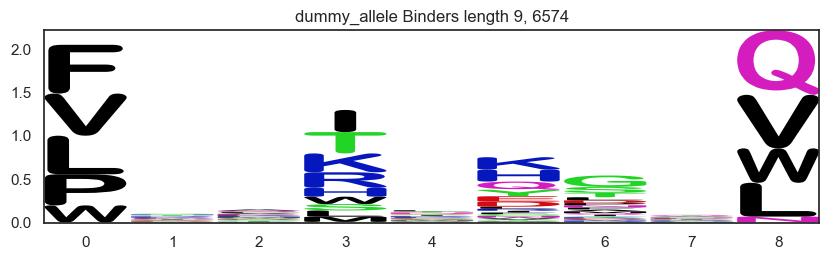

In [49]:
target_length = 9
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [50]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

def transform_data_to_properties_and_join_alleles(per_allele_per_kfold_per_length_binders_train,
                                                  per_allele_per_kfold_per_length_binders_test, ALLELES=ALLELES):
    per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
    per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

    if check_peptides:
        transform_dicts=None
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
        per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
        combination_size=combination_size,
        selected_alelles=ALLELES,
        total_splits=TOTAL_SPLITS,
        list_of_transform_dicts=None,position_component=params['position_component']
    )
    OLD_ALLELES = ALLELES
    NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
    ALLELES = NEW_ALLELES
    return per_allele_per_kfold_per_length_binders_train,  \
           per_allele_per_kfold_per_length_binders_test, ALLELES, \
           per_allele_per_kfold_per_length_binders_train_old, \
           per_allele_per_kfold_per_length_binders_test_old, \
           OLD_ALLELES




In [51]:
train_data, \
test_data, \
ALLELES, \
old_train_data, \
old_test_data, \
OLD_ALLELES, \
= transform_data_to_properties_and_join_alleles(
    per_allele_per_kfold_per_length_binders_train,
    per_allele_per_kfold_per_length_binders_test
)
ALLELES

dummy_allele
Length 9: dummy_allele - 6574 
Length 10: dummy_allele - 3668 
Length 11: dummy_allele - 1758 


['dummy_allele']

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [52]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

def get_weights(old_train_data):
    count_df_train = extract_count_df(old_train_data,
                                      selected_alleles=OLD_ALLELES,
                                      total_splits=TOTAL_SPLITS)
    # count_df_test = extract_count_df(old_test_data,
    #                                  selected_alleles=OLD_ALLELES,
    #                                  total_splits=TOTAL_SPLITS)
    # sub_count_df_train = count_df_train.loc[(count_df_train.index.get_level_values('split') == 0) &
    #                                     (count_df_train.index.get_level_values('allele').isin(ALLELES)) &
    #                                     (count_df_train.index.get_level_values('length').isin(TARGET_LENGTHS))]
    #per_allele_per_kfold_per_length_weights
    train_data_weigths =  calculate_weights_based_on_length_counts(count_df_train,
                                                                   selected_alleles=ALLELES,
                                                                   total_splits=TOTAL_SPLITS,
                                                                   selected_lengths=TARGET_LENGTHS,
                                                                   use_weights=USE_WEIGHTS)
    return train_data_weigths


## 2.3 Weights for data based on counts

In [53]:
train_data_weights = get_weights(old_train_data)

Total data length for split 0 is 12000
Weights for lentgh 9 are {'dummy_allele': 1.825372680255552}
Weights for lentgh 10 are {'dummy_allele': 3.271537622682661}
Weights for lentgh 11 are {'dummy_allele': 6.825938566552901}
Devide by 6.825938566552901
Combination dummy_allele, split 0: {9: array([0.2674171]), 10: array([0.47928026]), 11: array([1.])}
Total data length for split 1 is 12000
Weights for lentgh 9 are {'dummy_allele': 1.825372680255552}
Weights for lentgh 10 are {'dummy_allele': 3.271537622682661}
Weights for lentgh 11 are {'dummy_allele': 6.825938566552901}
Devide by 6.825938566552901
Combination dummy_allele, split 1: {9: array([0.2674171]), 10: array([0.47928026]), 11: array([1.])}
Total data length for split 2 is 12000
Weights for lentgh 9 are {'dummy_allele': 1.825372680255552}
Weights for lentgh 10 are {'dummy_allele': 3.271537622682661}
Weights for lentgh 11 are {'dummy_allele': 6.825938566552901}
Devide by 6.825938566552901
Combination dummy_allele, split 2: {9: arr

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code+

In [54]:
from hmm_logic_methods import train_model_prepared,  train_model_batched, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles_here



## 2.2 Train
### 2.2.1 Define treshold

In [55]:
per_allele_per_kfold_per_length_binders_train.keys()

dict_keys(['dummy_allele'])

In [56]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(train_data[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)

params['stop_threshold'] = stop_threshold

stop_threshold

9.598666666666666

### 2.2.2 Prepare  initial grouped structure models

In [57]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    IN_CYCLE_TR_PSEUDOCOUNT=params['in_cycle_tr_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    cycle_max_components=params['cycle_top_aas'],
    cycle_default_pseudocount=params['cycle_default_pseudocount'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states'],
    anchor_max_components=params['anchor_top_aas'],
    anchor_states=params['anchor_states'],
    model_complexity=params['model_complexity'],
    anchor_default_pseudocount= params['anchor_default_pseudocount'],
    tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
    position_component=params['position_component'],
    cycle_chain=params['cycle_chain']

)

start cycles added 0
end cycles added 0
states will be groups:15 + joiners:4 + start/end cycles:0 + int_cycles:0
One more time number of 'cycle' states 0 0
For example start cycle states []


In [58]:
from itertools import islice

In [59]:
prepared_model.dense_transition_matrix().shape

(21, 21)

In [60]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [61]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [62]:

make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=21 |E|=82

In [64]:
peptide = train_data[ALLELES[0]][0][9][0]

## Prepare models

In [65]:
ORIGINAL_RUNS = NUM_RUNS
NUM_RUNS = NUM_RUNS * 1



In [66]:
def prepare_all_models():
    per_allele_per_run_per_split_prepared_models = dict()
    for allele_name in ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
        per_allele_per_run_per_split_prepared_models[allele_name] = dict()
        for run_num in range(NUM_RUNS):
            per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
            for split_num in range(TOTAL_SPLITS):
                additional_anchor_acid = run_num// ORIGINAL_RUNS
                # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
                anchor_top_acids =params['anchor_top_aas'] + additional_anchor_acid
                prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                    states_per_group=int(params['states_per_group']),
                    number_of_groups=params['groups'],
                    IN_CYCLE_TR_PSEUDOCOUNT=params['in_cycle_tr_pseudocount'],
                    freeze_distr=params['freeze_distr'],
                    initial_params=initial_params,
                    start_cycle=params['start_cycle'],
                    end_cycle=params['end_cycle'],
                    self_cycles=params['self_cycle'],
                    discrete_distribution=check_peptides,
                    equal_probs_for_cycle=params['equal_probs_for_cycle'],
                    tie_cycle_states=params['tie_cycle_states'],
                     model_complexity=params['model_complexity'],
                         anchor_default_pseudocount= params['anchor_default_pseudocount'] ,
                 anchor_max_components=anchor_top_acids,
                    anchor_states=params['anchor_states'],
                       tie_anchor_states=params['tie_anchor_states'],
                        intermediate_cycles=params['intermediate_cycles'],
                        equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                        tie_intermediate_cycles=params['tie_intermediate_cycles'],
                        freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
                    position_component=params['position_component'],
        cycle_chain=params['cycle_chain'],
                )

                prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}-{anchor_top_acids}-aaas_model-{target_allele_name}-{split_num}'
                per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model
    return per_allele_per_run_per_split_prepared_models

In [67]:
per_allele_per_run_per_split_prepared_models = prepare_all_models()

start cycles added 0
end cycles added 0
states will be groups:15 + joiners:4 + start/end cycles:0 + int_cycles:0
One more time number of 'cycle' states 0 0
For example start cycle states []
start cycles added 0
end cycles added 0
states will be groups:15 + joiners:4 + start/end cycles:0 + int_cycles:0
One more time number of 'cycle' states 0 0
For example start cycle states []
start cycles added 0
end cycles added 0
states will be groups:15 + joiners:4 + start/end cycles:0 + int_cycles:0
One more time number of 'cycle' states 0 0
For example start cycle states []
start cycles added 0
end cycles added 0
states will be groups:15 + joiners:4 + start/end cycles:0 + int_cycles:0
One more time number of 'cycle' states 0 0
For example start cycle states []
start cycles added 0
end cycles added 0
states will be groups:15 + joiners:4 + start/end cycles:0 + int_cycles:0
One more time number of 'cycle' states 0 0
For example start cycle states []
start cycles added 0
end cycles added 0
states wil

In [68]:
TARGET_PATH_TO_RESULTS

'experiment_results/paper2_core_clustering/'

# Do training

In [69]:
def train_all_models(prepared_models,
                     train_data,
                     test_data,
                     train_data_weights,
                     save_dir= TARGET_PATH_TO_RESULTS
                     ):
    per_name_models = dict()
    per_name_histories = dict()
    result_histories = dict()
    result_models = dict()
    for allele_name in ALLELES:
        result_histories[allele_name] = dict()
        result_models[allele_name] = dict()
        for run_num in range(NUM_RUNS):
            print(f"run {run_num}")
            per_kfold_per_length_data = train_data[allele_name]
            per_kfold_per_length_weights = train_data_weights[allele_name]

            models, histories = train_model_prepared(
                                            per_kfold_per_length_data=per_kfold_per_length_data,
                                            per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                            target_lengths=TARGET_LENGTHS,
                                            multiple_check_input=params['multiple_check_input'],
                                            algorithm=params['alg'],
                                            verbose=params['verbose'],
                                            per_kfold_per_length_test_data=test_data[allele_name],
                                            stop_threshold=params['stop_threshold'],
                                            min_iterations= params['min_iters'],
                                            max_iterations=params['max_iters'],
                                            prepared_models=prepared_models[allele_name][run_num],
                                            emission_pseudocount=params['emission_pseudocount'],
                                            transition_pseudocount=params['transition_pseudocount'],
                                            edge_inertia=params['edge_inertia'],
                                            distribution_inertia=params['distribution_inertia'],
                                            lr_decay=params['lr_decay'],
                                            use_pseudocount=params['use_pseudocount'],
                                            minibatch_training=params['minibatch_training'],
                                            batches_per_epoch=params['batches_per_epoch'],
                                              batch_size=params['batch_size'],
                                           n_jobs=1)

            result_models[allele_name][run_num] = models
            result_histories[allele_name][run_num] = histories
            # per_allele_per_run_per_split_models[allele_name][run_num] = models
            for split_num, model in models.items():
                per_name_models[model.name] = model
            # save models
            for split_num, model in models.items():
                history = histories[split_num]
                save_model(save_dir, model,history)
    return result_models,\
           result_histories




In [70]:
%%time

import sys

# orig_stdout = sys.stdout
# f = open('training_log.log', 'w')
# sys.stdout = f

TOTAL_SPLITS = 1
result_models, \
result_histories = train_all_models(train_data=train_data,
                                  test_data=test_data,
                                  train_data_weights=train_data_weights,
                                  save_dir=TARGET_PATH_TO_RESULTS,
                                  prepared_models=per_allele_per_run_per_split_prepared_models
                                                              )
# sys.stdout = orig_stdout
# f.close()

run 0
split 0
train size 12000
Shuffling for fairness 
data shuffled
Example of data ['V', 'R', 'I', 'H', 'L', 'T', 'D', 'Y', 'H', 'S', 'L']
Mini_batch: Train Length 12000, batch_size 1, batches_per_epoch 100
Example of batch (array([list(['V', 'R', 'I', 'H', 'L', 'T', 'D', 'Y', 'H', 'S', 'L'])],
      dtype=object), array([1.]))
Use pseudocount is True
[1] Improvement: 28903.761007956287	Time (s): 0.2066
[2] Improvement: 6049.943895780249	Time (s): 0.2124
[3] Improvement: 1369.8926613326767	Time (s): 0.2053
[4] Improvement: 1298.2805735662696	Time (s): 0.2167
[5] Improvement: 851.2703449836699	Time (s): 0.23
[6] Improvement: 103.72228305245517	Time (s): 0.2101
[7] Improvement: -285.5625500836759	Time (s): 0.2091
[8] Improvement: 1060.4864315147279	Time (s): 0.214
[9] Improvement: 442.69460953673115	Time (s): 0.2133
[10] Improvement: 22.04823922732612	Time (s): 0.2071
[11] Improvement: 421.9499125140137	Time (s): 0.2208
[12] Improvement: 515.5063950401382	Time (s): 0.2083
[13] Improvem

In [76]:
TARGET_PATH_TO_SORTED_RESULTS = f"{TARGET_PATH_TO_RESULTS}/sorted_models/"

def reorder_models_by_score(histories, models, path_to_save=TARGET_PATH_TO_SORTED_RESULTS):
    # Sort by score
    per_name_new_models = dict()
    per_name_histories = dict()
    per_split_allele_original_sortings = dict()
    for split_num in range(TOTAL_SPLITS):
        per_split_allele_original_sortings[split_num] = dict()
        for allele_name in ALLELES:
            df = pd.DataFrame({"model": np.arange(NUM_RUNS),
                              "log_probability": [histories[allele_name][i][split_num].log_probabilities[-1]
                                                 for i in range(NUM_RUNS)],
                             # "test_log_probability":  [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].test_log_probability[-1]
                              #                   for i in range(NUM_RUNS)]
                              })
            df = df.sort_values(by='log_probability', ascending = False).reset_index(drop=True)
            per_split_allele_original_sortings[split_num][allele_name] = df
            for new_index, model_run_num in zip(np.arange(len(df)), df.model):
                original_model =  models[allele_name][model_run_num][split_num]
                original_history = histories[allele_name][model_run_num][split_num]
                original_model_name = original_model.name
                rest_part = original_model_name.split("_", 1)[1]
                new_name = f"{new_index}_{rest_part}"
                original_model.name = new_name
                per_name_new_models[new_name] = original_model
                per_name_histories[new_name] = original_history
    per_name_models = per_name_new_models
    for name, model in per_name_models.items():
        history = per_name_histories[name]
        save_model(path_to_save, model,history)
    return per_name_models, per_name_histories, per_split_allele_original_sortings



In [77]:

per_name_models, per_name_histories, original_alelle_sortings = reorder_models_by_score(histories=result_histories,
                                                                models=result_models)


In [78]:
from hmm_visualization_methods import *
def save_all_visualization_results(per_name_models, per_name_histories, save_dir=TARGET_PATH_TO_SORTED_RESULTS):

    #learning curve
    fig, ax = plt.subplots(1, 1)
    for i in range(1):
        sns.lineplot(
            per_name_histories[
                list(per_name_histories.keys())[i]
            ].log_probabilities, ax=ax)

    print('\nModelGraph')
    for i, model in enumerate(per_name_models.values()):
        print(i, end=' ')
        # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
        #     model.plot(file=f, crop_zero=False)
        with open(f"{save_dir}{model.name}/state_graph_cropped.png", 'w+') as f:
            model.plot(file=f, crop_zero=True)
    print('\nDistributions')
    for i, model in enumerate(per_name_models.values()):
        print(i, end=' ')
        plot_distributions_for_states(model,save_dir, horizontal=False, discrete=check_peptides, initial_params=initial_params)

    print('\nPyViz')
    per_name_pyviz = dict()
    for name, model in per_name_models.items():
        per_name_pyviz[name] = make_pyviz_graph(model, save_dir, precision=3)



In [79]:
TARGET_PATH_TO_RESULTS

'experiment_results/paper2_core_clustering/'


ModelGraph
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 
Distributions
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 
PyViz
Converting graph for model (0_run-9-10-11-15-st-viterbi-alg-60-min_iters-4-aaas_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (1_run-9-10-11-15-st-viterbi-alg-60-min_iters-4-aaas_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (2_run-9-10-11-15-st-viterbi-alg-60-min_iters-4-aaas_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (3_run-9-10-11-15-st-viterbi-alg-60-min_iters-4-aaas_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (4_run-9-10-11-15-st-viterbi-alg-60-min_iters-4-aaas_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (5_run-9-10-11-15-st-viterbi-alg-60-min_iters-4-aaas_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (6_run-9-10-11-15-st-viterbi-alg-60-min_iters-4

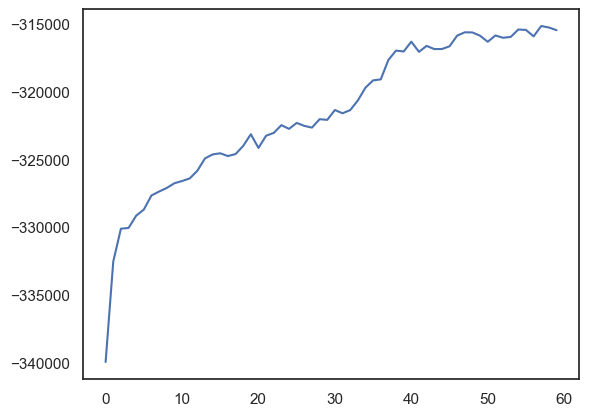

In [80]:
save_all_visualization_results(per_name_models, per_name_histories)